# Digital Marketing Campaigns: What Drives Conversion?

**Igor M. Lopes** · MS Business Analytics & Project Management, University of Connecticut · Independent project

## Business question
A marketing team runs campaigns across five channels and four campaign types. Which campaign and customer factors are associated with conversion? Can we predict which customers will **not** convert, so spend and follow-up can be targeted?

## Key findings
* **88% of customers convert**, so a model that always predicts "converts" is 88% accurate and useless. Models are judged on ROC-AUC and on how many **non-converters** they catch.
* **Campaign type matters, channel doesn't.** "Conversion" campaigns convert 93% vs about 86% for Awareness, Consideration and Retention (χ² p < 0.001). Differences between channels are not significant (p = 0.59). Neither are differences by gender (p = 0.95).
* **Engagement and loyalty drive conversion.** Time on site, email engagement, past purchases and ad spend separate converters from non-converters. Age and income don't.
* **Random forest:** test **ROC-AUC 0.79** (cross-validated 0.82). It identifies 55% of non-converters with 53% precision, where the baseline catches 0%.
* **Engagement segments:** conversion rises from **79% (low engagement) to 94% (high)**.

**Note:** this is a synthetic Kaggle dataset, so the findings show the method rather than describe a real company.

**Tools:** Python (pandas, SciPy, scikit-learn), SQL (SQLite) · **Data:** [Predict Conversion in Digital Marketing](https://www.kaggle.com/datasets/rabieelkharoua/predict-conversion-in-digital-marketing-dataset)

## 1. Setup

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

candidates = list(Path('/kaggle/input').rglob('digital_marketing_campaign_dataset.csv')) if Path('/kaggle/input').exists() else []
candidates += [Path('../data/digital_marketing_campaign_dataset.csv'), Path('data/digital_marketing_campaign_dataset.csv')]
DATA_FILE = next(p for p in candidates if p.exists())
FIG_DIR = Path('../figures') if Path('../figures').exists() else Path('figures')
FIG_DIR.mkdir(exist_ok=True)

pd.set_option('display.float_format', '{:,.3f}'.format)
plt.rcParams.update({'font.size': 12, 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, LIGHT_BLUE, RED, GREY = '#2B6CB0', '#ADD8E6', '#E05252', '#9AA5B1'

## 2. Data overview and quality

In [2]:
df = pd.read_csv(DATA_FILE)
print(df.shape)
print('Missing values:', df.isna().sum().sum(), '| duplicate customers:', df['CustomerID'].duplicated().sum())
print('Constant columns:', [c for c in df.columns if df[c].nunique() == 1])
df = df.drop(columns=['AdvertisingPlatform', 'AdvertisingTool'])   # one value each: no information
print(f"Conversion rate: {df['Conversion'].mean():.1%} ({df['Conversion'].sum():,} of {len(df):,})")
df.head()

(8000, 20)
Missing values: 0 | duplicate customers: 0
Constant columns: ['AdvertisingPlatform', 'AdvertisingTool']
Conversion rate: 87.6% (7,012 of 8,000)


,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,Conversion
0,8000,56,Female,136912,Social Media,Awareness,"6,497.870",0.044,0.088,0,2.399,7.397,19,6,9,4,688,1
1,8001,69,Male,41760,Email,Retention,"3,898.669",0.156,0.183,42,2.917,5.353,5,2,7,2,3459,1
2,8002,46,Female,88456,PPC,Awareness,"1,546.430",0.277,0.076,2,8.224,13.795,0,11,2,8,2337,1
3,8003,32,Female,44085,PPC,Conversion,539.526,0.138,0.088,47,4.541,14.688,89,2,2,0,2463,1
4,8004,60,Female,83964,PPC,Conversion,"1,678.044",0.253,0.110,0,2.047,13.993,6,6,6,8,4345,1


The data is complete, with no missing values or duplicates. Two columns hold a single placeholder value ("IsConfid"/"ToolConfid") and are dropped. The target is **imbalanced**: 88% converted, 12% did not.

## 3. Campaign factors: type, channel and gender

In [3]:
rows = []
for col in ['CampaignType', 'CampaignChannel', 'Gender']:
    table = pd.crosstab(df[col], df['Conversion'])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    rows.append([col, chi2, dof, p])
    display(df.groupby(col)['Conversion'].agg(customers='size', conversion_rate='mean').sort_values('conversion_rate', ascending=False))
pd.DataFrame(rows, columns=['Factor', 'Chi-square', 'df', 'p-value'])

,customers,conversion_rate
CampaignType,,
Conversion,2077,0.934
Retention,1947,0.858
Consideration,1988,0.856
Awareness,1988,0.856


,customers,conversion_rate
CampaignChannel,,
Referral,1719,0.883
PPC,1655,0.883
SEO,1550,0.877
Email,1557,0.870
Social Media,1519,0.868


,customers,conversion_rate
Gender,,
Male,3161,0.877
Female,4839,0.876


,Factor,Chi-square,df,p-value
0,CampaignType,84.454,3,0.000
1,CampaignChannel,2.785,4,0.594
2,Gender,0.004,1,0.951


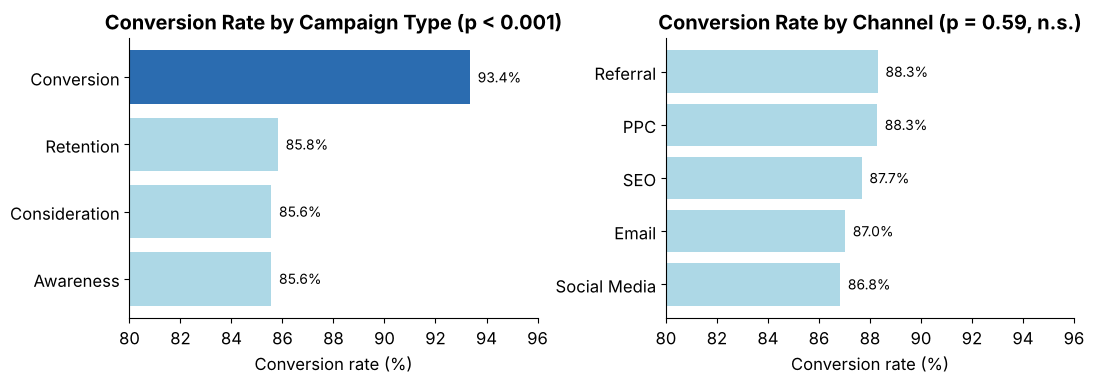

In [4]:
by_type = df.groupby('CampaignType')['Conversion'].mean().sort_values()
by_channel = df.groupby('CampaignChannel')['Conversion'].mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, s, title in [(axes[0], by_type, 'Campaign Type (p < 0.001)'), (axes[1], by_channel, 'Channel (p = 0.59, n.s.)')]:
    ax.barh(s.index, s.values * 100, color=[BLUE if v == s.max() and 'Type' in title else LIGHT_BLUE for v in s.values])
    for i, v in enumerate(s.values): ax.text(v * 100 + 0.3, i, f'{v:.1%}', va='center', fontsize=10)
    ax.set(title=f'Conversion Rate by {title}', xlim=(80, 96), xlabel='Conversion rate (%)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'conversion_by_campaign.png', dpi=150); plt.show()

* **Campaign type is the only campaign factor that matters.** Conversion-focused campaigns convert 93%, about 8 points above the others.
* **Channel differences (86.8%–88.3%) are within random variation.** Budget shouldn't be moved between channels based on these differences alone.
* **Gender has no effect.**

## 4. Customer behaviour: converters vs non-converters

In [5]:
NUM = ['Age', 'Income', 'AdSpend', 'ClickThroughRate', 'WebsiteVisits', 'PagesPerVisit', 'TimeOnSite',
       'SocialShares', 'EmailOpens', 'EmailClicks', 'PreviousPurchases', 'LoyaltyPoints']
rows = []
for c in NUM:
    a, b = df.loc[df.Conversion == 1, c], df.loc[df.Conversion == 0, c]
    pooled = np.sqrt((a.var() + b.var()) / 2)
    rows.append([c, a.mean(), b.mean(), (a.mean() - b.mean()) / pooled, stats.mannwhitneyu(a, b).pvalue])
diff = (pd.DataFrame(rows, columns=['Variable', 'Converted mean', 'Not converted mean', "Effect size (Cohen's d)", 'Mann-Whitney p'])
          .sort_values("Effect size (Cohen's d)", ascending=False).reset_index(drop=True))
diff

,Variable,Converted mean,Not converted mean,Effect size (Cohen's d),Mann-Whitney p
0,TimeOnSite,7.933,6.268,0.396,0.000
1,EmailClicks,4.606,3.482,0.396,0.000
2,AdSpend,"5,133.751","4,058.398",0.390,0.000
3,EmailOpens,9.745,7.577,0.379,0.000
4,ClickThroughRate,0.159,0.128,0.365,0.000
5,PreviousPurchases,4.607,3.626,0.330,0.000
6,PagesPerVisit,5.650,4.835,0.304,0.000
7,LoyaltyPoints,"2,541.244","2,128.484",0.285,0.000
8,WebsiteVisits,25.178,21.727,0.234,0.000
9,Income,"84,861.302","83,265.309",0.042,0.210


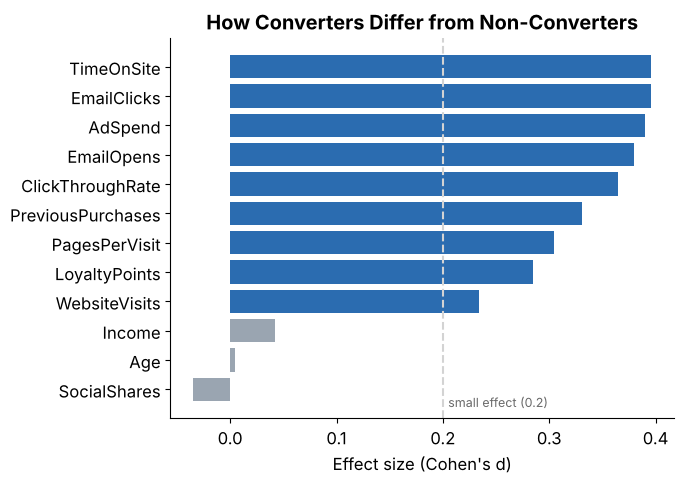

In [6]:
d = diff.set_index('Variable')["Effect size (Cohen's d)"].sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(d.index, d.values, color=[BLUE if abs(v) >= 0.2 else GREY for v in d.values])
ax.axvline(0.2, color='lightgray', ls='--'); ax.text(0.205, -0.6, 'small effect (0.2)', fontsize=9, color='dimgray')
ax.set(title='How Converters Differ from Non-Converters', xlabel="Effect size (Cohen's d)")
fig.tight_layout(); fig.savefig(FIG_DIR / 'converter_differences.png', dpi=150); plt.show()

Converters spend more **time on site**, open and click more **emails**, received more **ad spend**, and have more **previous purchases** and **loyalty points**. Each of these differences is small to moderate. **Age and income show no meaningful difference.** Behaviour matters more than demographics.

## 5. Engagement segmentation
Engagement variables use very different units: visits, minutes, opens. Each is standardized (z-score) before averaging into one **engagement score**. Customers are then split into thirds.

In [7]:
ENGAGEMENT = ['WebsiteVisits', 'PagesPerVisit', 'TimeOnSite', 'EmailOpens', 'EmailClicks', 'SocialShares']
z = (df[ENGAGEMENT] - df[ENGAGEMENT].mean()) / df[ENGAGEMENT].std()
df['EngagementScore'] = z.mean(axis=1)
df['EngagementSegment'] = pd.qcut(df['EngagementScore'], 3, labels=['Low', 'Medium', 'High'])
seg = df.groupby('EngagementSegment', observed=True).agg(customers=('Conversion', 'size'), conversion_rate=('Conversion', 'mean'),
                                                         avg_time_on_site=('TimeOnSite', 'mean'), avg_email_clicks=('EmailClicks', 'mean'))
print('Chi-square p =', stats.chi2_contingency(pd.crosstab(df['EngagementSegment'], df['Conversion']))[1])
seg

Chi-square p = 5.167617336324381e-63


,customers,conversion_rate,avg_time_on_site,avg_email_clicks
EngagementSegment,,,,
Low,2667,0.793,5.835,3.153
Medium,2666,0.894,7.722,4.464
High,2667,0.943,9.626,5.785


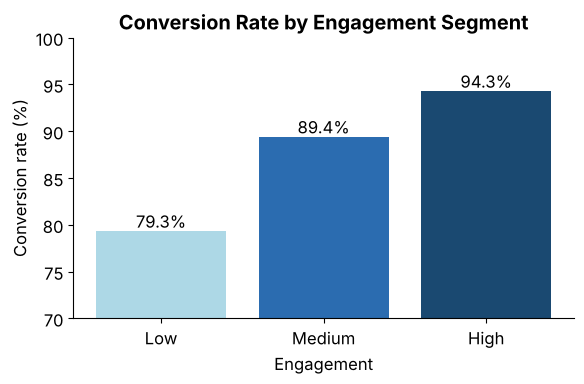

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(seg.index.astype(str), seg['conversion_rate'] * 100, color=[LIGHT_BLUE, BLUE, '#1A4971'])
for i, v in enumerate(seg['conversion_rate']): ax.text(i, v * 100 + 0.4, f'{v:.1%}', ha='center')
ax.set(title='Conversion Rate by Engagement Segment', ylabel='Conversion rate (%)', ylim=(70, 100), xlabel='Engagement')
fig.tight_layout(); fig.savefig(FIG_DIR / 'engagement_segments.png', dpi=150); plt.show()

## 6. SQL analysis

In [9]:
con = sqlite3.connect(':memory:')
df.drop(columns=['EngagementSegment']).to_sql('campaigns', con, index=False)
SQL = """-- Conversion rate by campaign type and channel
SELECT CampaignType,
       COUNT(*)                         AS customers,
       SUM(Conversion)                  AS converted,
       ROUND(100.0 * AVG(Conversion), 1) AS conversion_rate_pct,
       ROUND(AVG(AdSpend), 0)           AS avg_ad_spend
FROM campaigns
GROUP BY CampaignType
ORDER BY conversion_rate_pct DESC;

-- Channel performance ranked with a window function
SELECT CampaignChannel,
       COUNT(*)                                         AS customers,
       ROUND(100.0 * AVG(Conversion), 1)                AS conversion_rate_pct,
       RANK() OVER (ORDER BY AVG(Conversion) DESC)      AS channel_rank
FROM campaigns
GROUP BY CampaignChannel;

-- Conversion by number of previous purchases (bucketed)
SELECT CASE WHEN PreviousPurchases <= 2 THEN '0-2'
            WHEN PreviousPurchases <= 5 THEN '3-5'
            ELSE '6+' END                   AS previous_purchases,
       COUNT(*)                             AS customers,
       ROUND(100.0 * AVG(Conversion), 1)    AS conversion_rate_pct
FROM campaigns
GROUP BY previous_purchases
ORDER BY previous_purchases;
"""
for query in [q.strip() for q in SQL.split(';') if q.strip()]:
    display(pd.read_sql(query, con))

,CampaignType,customers,converted,conversion_rate_pct,avg_ad_spend
0,Conversion,2077,1939,93.400,"4,959.000"
1,Retention,1947,1671,85.800,"5,017.000"
2,Consideration,1988,1701,85.600,"4,960.000"
3,Awareness,1988,1701,85.600,"5,069.000"


,CampaignChannel,customers,conversion_rate_pct,channel_rank
0,Referral,1719,88.300,1
1,PPC,1655,88.300,2
2,SEO,1550,87.700,3
3,Email,1557,87.000,4
4,Social Media,1519,86.800,5


,previous_purchases,customers,conversion_rate_pct
0,0-2,2405,81.000
1,3-5,2398,91.000
2,6+,3197,90.200


## 7. Predicting non-conversion
**Goal:** flag customers unlikely to convert. With 88% converting, accuracy is misleading, so models are compared on **ROC-AUC** and on **recall for non-converters**. Classes are balanced during training.

`ConversionRate` is left out of the features because it is itself a conversion outcome. Using it to predict conversion would be circular.

In [10]:
CAT = ['Gender', 'CampaignChannel', 'CampaignType']
X, y = df[NUM + CAT], df['Conversion']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
prep = make_column_transformer((StandardScaler(), NUM), (OneHotEncoder(drop='first'), CAT))

models = {
    'Baseline (always "converts")': make_pipeline(prep, DummyClassifier(strategy='most_frequent')),
    'Logistic regression': make_pipeline(prep, LogisticRegression(class_weight='balanced', max_iter=2000)),
    'Random forest': make_pipeline(prep, RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                                                class_weight='balanced', random_state=42, n_jobs=-1)),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows, probs = [], {}
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    model.fit(X_train, y_train)
    pred, probs[name] = model.predict(X_test), model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append([name, (pred == y_test).mean(), cv_auc.mean(), roc_auc_score(y_test, probs[name]),
                 tn / (tn + fp), tn / (tn + fn) if tn + fn else np.nan])
pd.DataFrame(rows, columns=['Model', 'Accuracy', 'CV AUC', 'Test AUC', 'Non-converter recall', 'Non-converter precision'])

,Model,Accuracy,CV AUC,Test AUC,Non-converter recall,Non-converter precision
0,"Baseline (always ""converts"")",0.876,0.500,0.500,0.000,NaN
1,Logistic regression,0.736,0.790,0.770,0.717,0.278
2,Random forest,0.883,0.821,0.793,0.547,0.525


               precision    recall  f1-score   support

Not converted       0.53      0.55      0.54       247
    Converted       0.94      0.93      0.93      1753

     accuracy                           0.88      2000
    macro avg       0.73      0.74      0.73      2000
 weighted avg       0.89      0.88      0.88      2000



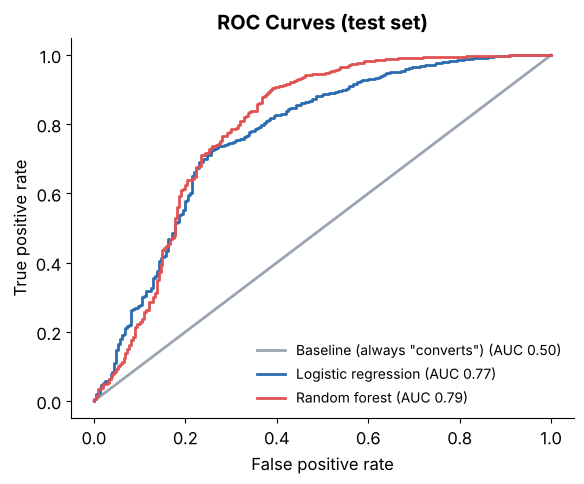

In [11]:
print(classification_report(y_test, models['Random forest'].predict(X_test), target_names=['Not converted', 'Converted']))
fig, ax = plt.subplots(figsize=(6, 5))
for (name, p), color in zip(probs.items(), [GREY, BLUE, RED]):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC {roc_auc_score(y_test, p):.2f})')
ax.set(title='ROC Curves (test set)', xlabel='False positive rate', ylabel='True positive rate')
ax.legend(frameon=False, loc='lower right', fontsize=10); fig.tight_layout(); fig.savefig(FIG_DIR / 'roc_curves.png', dpi=150); plt.show()

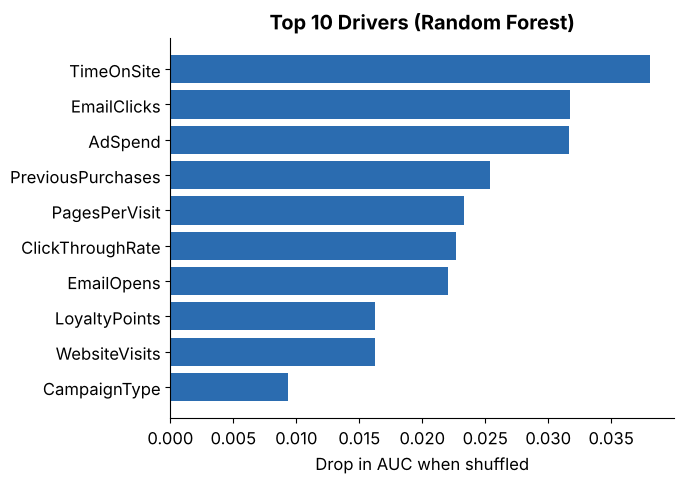

In [12]:
imp = permutation_importance(models['Random forest'], X_test, y_test, scoring='roc_auc', n_repeats=15, random_state=42)
importance = pd.Series(imp.importances_mean, index=NUM + CAT).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance.values, color=BLUE)
ax.set(title='Top 10 Drivers (Random Forest)', xlabel='Drop in AUC when shuffled')
fig.tight_layout(); fig.savefig(FIG_DIR / 'feature_importance.png', dpi=150); plt.show()

* The **baseline** is 88% accurate but catches **no** non-converters (AUC 0.50). This is the trap in reporting accuracy alone.
* The **random forest** (AUC 0.79) catches 55% of non-converters with 53% precision. **Logistic regression** (AUC 0.77) catches more non-converters (72%) but with many false alarms (28% precision). Which to use depends on the cost of a follow-up action.
* Engagement and loyalty variables drive the predictions. That matches the effect sizes in section 4.

## 8. Recommendations
1. **Prioritize conversion-focused campaign types.** They outperform awareness, consideration and retention campaigns by about 8 points.
2. **Don't shift budget between channels on these results.** Channel differences are not statistically significant.
3. **Grow engagement.** Low-engagement customers convert 15 points less than high-engagement ones. Use email nurture and on-site content to raise time on site and clicks.
4. **Use the model to target follow-up.** Score customers before the campaign closes and send reminders or offers to those flagged as likely non-converters.

## Limitations
* The dataset is **synthetic**, so effects are smaller and cleaner than in real campaign data.
* There are no timestamps, so the analysis can't tell whether engagement came before conversion. These are associations, not causes.